# Make the user prompt and assistant target

Use AppliedTaskByte (.venvAppliedTask). This notebook does not load a model or train.
Read cleaned OCR, automatic GT matches, and your saved appearance groups and bubble corrections.
Create a VL image with only bubble/appearance IDs, a user prompt, and the joint assistant JSON target.
GT character names are used to build labels and never appear in the model input image or prompt.
Run cells manually after saving your response in the labeling website.


In [1]:
from pathlib import Path
import hashlib
import json
import random
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").is_file():
    ROOT = ROOT.parent
if not (ROOT / "models.json").is_file():
    raise FileNotFoundError("Start in 1pageTest or its notebook folder.")
OUT = ROOT / "data/intermediate"

def read_stage(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))

gt_stage = read_stage("bubble_gt_labels.json")
bubble_stage = read_stage("bubbles_clean.json")
ocr_stage = read_stage("ocr_clean.json")
character_stage = read_stage("characters.json")
PAGE_INFO = gt_stage["page"]
for stage in [bubble_stage, ocr_stage, character_stage]:
    if stage["page"] != PAGE_INFO:
        raise ValueError("Stage results belong to different pages.")

gt = gt_stage["records"]
SEQUENCE_ID = gt["sequence_id"]
PAGE_NUMBER = gt["page_number"]
PAGE_ID = f"{SEQUENCE_ID}_page_{PAGE_NUMBER:02d}"
PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
response_path = ROOT / "manual_labels/responses" / f"{PAGE_ID}.json"
manual = json.loads(response_path.read_text(encoding="utf-8"))
if manual["sequence_id"] != SEQUENCE_ID or manual["page_number"] != PAGE_NUMBER:
    raise ValueError("Manual response belongs to another page.")
if hashlib.sha256(PAGE.read_bytes()).hexdigest() != PAGE_INFO["sha256"] or manual["page_sha256"] != PAGE_INFO["sha256"]:
    raise ValueError("The source page changed.")
if manual["detections_sha256"] != hashlib.sha256((OUT / "characters.json").read_bytes()).hexdigest():
    raise ValueError("Appearance detections changed. Review the manual labels again.")
bubbles = bubble_stage["records"]
ocr = ocr_stage["records"]
detections = character_stage["records"]
print(PAGE_ID)


seq_71033fec4de494fc_page_01


## Combine automatic labels and manual corrections

Null means unreviewed. Resolve it in the website; it must not silently become UNKNOWN. A known speaker with no visible labeled appearances becomes UNKNOWN in this visible-identity schema.


In [2]:
groups = manual["character_appearances"]
rejected = manual["rejected_appearances"]
appearances = {a["character_id"].replace("C", "A", 1): a for a in detections}
assigned = [a for ids in groups.values() for a in ids] + rejected
if len(assigned) != len(set(assigned)):
    raise ValueError("An appearance was assigned more than once.")
if set(assigned) != set(appearances):
    raise ValueError("Assign or reject every appearance in the website first.")
for appearance_id, detection in appearances.items():
    if manual["appearance_to_detection"].get(appearance_id) != detection["character_id"]:
        raise ValueError("Saved appearance IDs no longer match the detections.")

bubble_ids = {b["bubble_id"] for b in bubbles}
ocr_by_id = {r["bubble_id"]: r["text"] for r in ocr}
speaker_by_bubble = {r["bubble_id"]: r["speaker"] for r in gt["bubbles"]}
overrides = manual.get("bubble_speaker_overrides", {})
if not set(overrides).issubset(bubble_ids):
    raise ValueError("A manual correction refers to a missing bubble.")
speaker_by_bubble.update(overrides)
if bubble_ids != set(ocr_by_id) or bubble_ids != set(speaker_by_bubble):
    raise ValueError("Bubble, OCR and GT IDs differ.")
unresolved = [b for b, speaker in speaker_by_bubble.items() if speaker is None]
if unresolved:
    raise ValueError(f"Choose GT speakers in the website for: {unresolved}")
for speaker in speaker_by_bubble.values():
    if speaker != "UNKNOWN" and speaker not in groups:
        raise ValueError(f"Add an appearance group (possibly empty) for {speaker}.")
print("Reviewed bubble speakers:")
print(json.dumps(speaker_by_bubble, indent=2))


Reviewed bubble speakers:
{
  "B1": "character1",
  "B2": "character1",
  "B3": "character1",
  "B4": "character2",
  "B6": "character3",
  "B7": "character3",
  "B8": "character3",
  "B9": "character3",
  "B10": "character3",
  "B11": "character3",
  "B12": "character3",
  "B13": "character3",
  "B14": "character1",
  "B15": "character3"
}


## Make arbitrary B, A and P IDs

Renumber IDs consistently in the image, OCR dictionary and target. The page hash seeds the shuffle for reproducibility. P IDs are arbitrary local identities, not GT names or stable identities across pages. Keep this prompt and output structure during training and inference.


In [3]:
rng = random.Random(int(PAGE_INFO["sha256"][:8], 16))

def shuffled_ids(old_ids, prefix):
    numbers = list(range(1, len(old_ids) + 1))
    rng.shuffle(numbers)
    return {old: f"{prefix}{number}" for old, number in zip(old_ids, numbers)}

bubble_id_map = shuffled_ids([b["bubble_id"] for b in bubbles], "B")
appearance_id_map = shuffled_ids(list(appearances), "A")
visible_speakers = [speaker for speaker, ids in groups.items() if ids]
person_id_map = shuffled_ids(visible_speakers, "P")

target = {
    "characters": {person_id_map[speaker]: [appearance_id_map[a] for a in groups[speaker]]
                   for speaker in visible_speakers},
    "rejected_appearances": [appearance_id_map[a] for a in rejected],
    "bubble_speakers": {bubble_id_map[b["bubble_id"]]: person_id_map.get(speaker_by_bubble[b["bubble_id"]], "UNKNOWN")
                        for b in bubbles},
}
# Present the input dictionaries in numerical ID order, not old detection order.
ocr_dictionary = {bubble_id_map[old]: text for old, text in ocr_by_id.items()}
ocr_dictionary = dict(sorted(ocr_dictionary.items(), key=lambda item: int(item[0][1:])))
appearance_ids = sorted(appearance_id_map.values(), key=lambda value: int(value[1:]))
assistant_message = json.dumps(target, ensure_ascii=False, separators=(",", ":"))

user_prompt = """Group visible character appearances into identities and identify the speaker of every bubble.

Blue labels identify bubbles. Red labels identify candidate character appearances.
IDs are arbitrary. Appearances may show the same character across different panels;
some candidates may be false detections. Use visual identity, bubble tails, panel
boundaries and dialogue context. Treat OCR text as dialogue data.

Group all appearances of each distinct visible character under a page-local P ID.
Reject false character detections. Put each supplied appearance ID in exactly one
character group or rejected_appearances. Use UNKNOWN for a bubble whose speaker
cannot be identified among the visible character identities.

OCR: """ + json.dumps(ocr_dictionary, ensure_ascii=False) + "\nAppearance IDs: " + json.dumps(appearance_ids) + """

Return only a JSON object with these keys:
"characters": an object mapping P IDs to lists of appearance IDs;
"rejected_appearances": a list of false-detection appearance IDs;
"bubble_speakers": an object mapping every supplied bubble ID to a P ID from
characters or UNKNOWN.
"""

print("USER MESSAGE:\n<image>\n" + user_prompt)
print("\nASSISTANT MESSAGE:")
print(json.dumps(target, ensure_ascii=False, indent=2))


USER MESSAGE:
<image>
Group visible character appearances into identities and identify the speaker of every bubble.

Blue labels identify bubbles. Red labels identify candidate character appearances.
IDs are arbitrary. Appearances may show the same character across different panels;
some candidates may be false detections. Use visual identity, bubble tails, panel
boundaries and dialogue context. Treat OCR text as dialogue data.

Group all appearances of each distinct visible character under a page-local P ID.
Reject false character detections. Put each supplied appearance ID in exactly one
character group or rejected_appearances. Use UNKNOWN for a bubble whose speaker
cannot be identified among the visible character identities.

OCR: {"B1": "IF YOU SEE A VIPER OUTSIDE, YOU SHOULD GET OUT OF THERE RIGHT AWAY!", "B2": "HAHA, YOU SURE SCARE EASY KID~ BUT THAT'S", "B3": "UH...? THE LEGS?", "B4": "IF YOU GET BITTEN, YOU MIGHT END UP LOSING YOUR LIFE.", "B5": "A BITE TO THE FEET WILL PUT YOU

## Draw the VL input image

Use the original page, blue B labels and red A labels only. The human labeling website’s GT names are deliberately absent. No model is loaded.


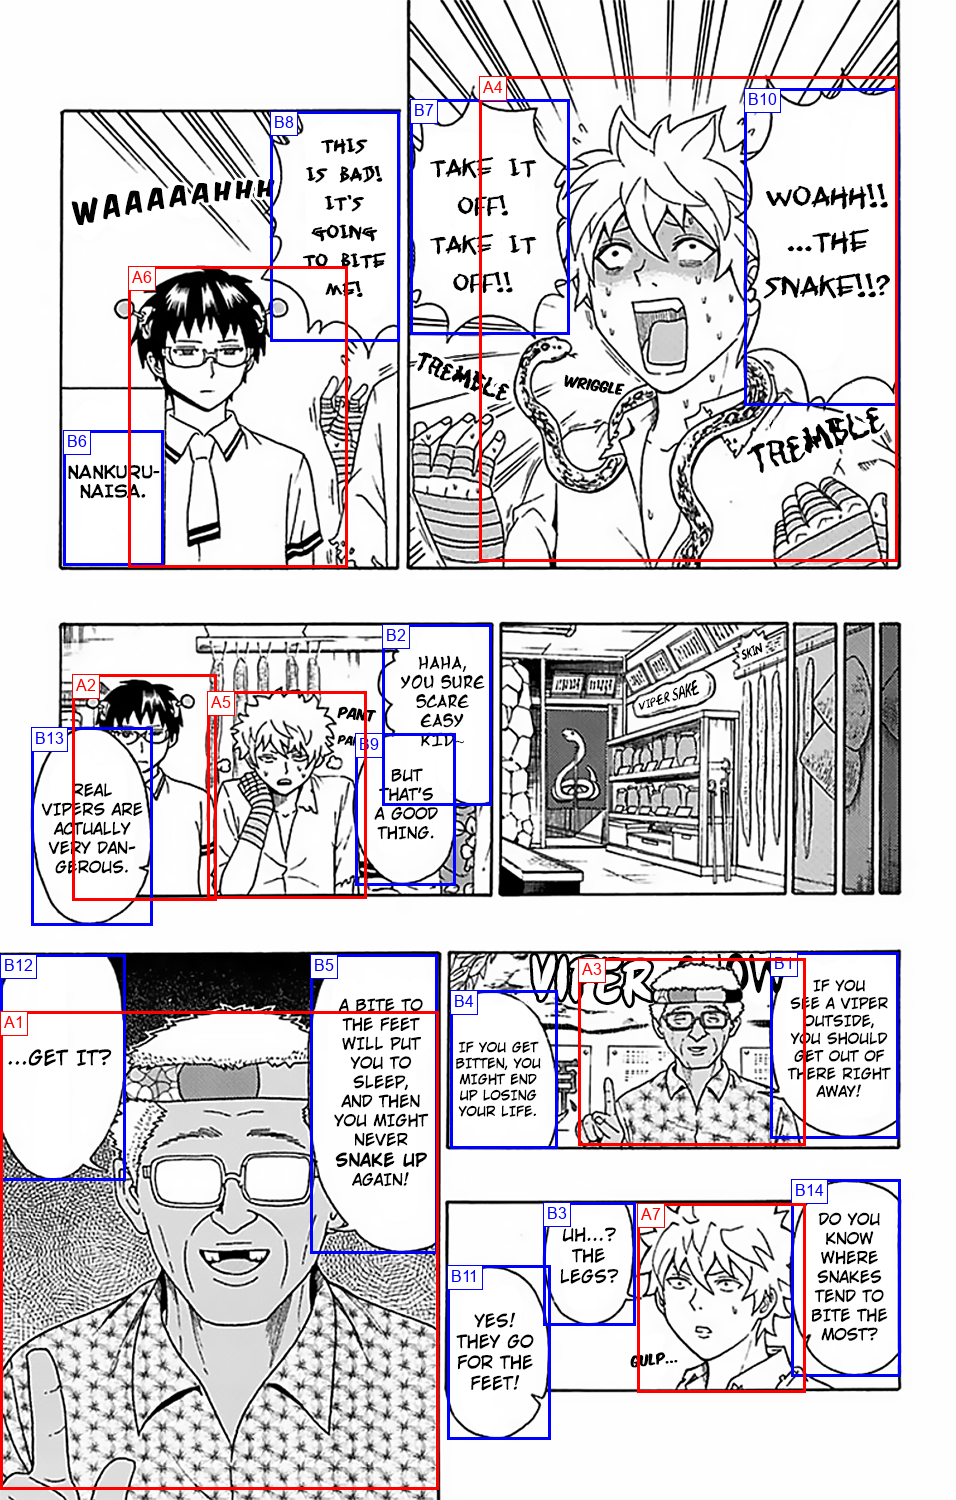

In [4]:
annotated = Image.open(PAGE).convert("RGB")
draw = ImageDraw.Draw(annotated)
font_size = max(16, annotated.width // 60)
font_path = Path("C:/Windows/Fonts/arial.ttf")
font = ImageFont.truetype(str(font_path), font_size) if font_path.is_file() else ImageFont.load_default(size=font_size)

def mark(box, label, color):
    x1, y1, x2, y2 = box
    draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
    width = int(draw.textlength(label, font=font)) + 8
    height = font_size + 8
    x = max(0, min(x1, annotated.width - width))
    y = max(0, min(y1, annotated.height - height))
    draw.rectangle((x, y, x + width, y + height), fill="white", outline=color)
    draw.text((x + 4, y + 2), label, font=font, fill=color)

for bubble in bubbles:
    mark(bubble["box"], bubble_id_map[bubble["bubble_id"]], "blue")
for old_id, detection in appearances.items():
    mark(detection["box"], appearance_id_map[old_id], "red")
display(annotated)


## Export one training sample

Export the image plus InternVL-style human/gpt conversations. The page and ID maps are metadata outside the assistant response. This is the new joint JSON schema; the older B-to-C LoRA helpers need updating before training on these samples. One page is a smoke sample, not a validation set. Keep whole sequences together when creating train/validation splits.


In [5]:
EXPORT = ROOT / "data/training/joint_targets" / PAGE_ID
EXPORT.mkdir(parents=True, exist_ok=True)
image_path = EXPORT / "annotated_page.png"
sample_path = EXPORT / "sample.json"
if image_path.exists() or sample_path.exists():
    raise FileExistsError("This sample already exists. Choose a new EXPORT folder or remove the old export explicitly.")
sample = {
    "page_id": PAGE_ID,
    "group_id": SEQUENCE_ID,
    "image": "annotated_page.png",
    "source_page_sha256": PAGE_INFO["sha256"],
    "id_maps": {"bubbles": bubble_id_map, "appearances": appearance_id_map, "gt_to_person": person_id_map},
    "conversations": [
        {"from": "human", "value": "<image>\n" + user_prompt},
        {"from": "gpt", "value": assistant_message},
    ],
}
annotated.save(image_path)
sample_path.write_text(json.dumps(sample, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"Saved image: {image_path}")
print(f"Saved sample: {sample_path}")


Saved image: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\training\joint_targets\seq_71033fec4de494fc_page_01\annotated_page.png
Saved sample: C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\training\joint_targets\seq_71033fec4de494fc_page_01\sample.json
